In [1]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.value import Params, add_value
from src.segments import ringkas_segmen, URUT
from src.strategies import select_targets

sc = pd.read_parquet("../data/scored.parquet"); P = Params(); v = add_value(sc, P)

t = ringkas_segmen(v, P)
print(t.to_string(index=False))
assert t["n"].sum() == 7043
assert abs(t["nyata_layak"].sum() - 92.652884) < 0.01   # cocok dengan Step 14 (Rp juta)
t.to_csv("../reports/segments.csv", index=False)

monthly_charge_band   keterlibatan    n  churn  p_rata  layak  ev_layak  nyata_layak  porsi_untung  kecil
           1-Rendah     Proteksi 0  110    0.5   0.463  0.800     0.700        0.817         0.009  False
           1-Rendah   Proteksi 1-2  207  0.275   0.259  0.604     0.693        0.792         0.009  False
           1-Rendah   Proteksi 3-4   46  0.065   0.079  0.109     0.028        0.044         0.000   True
           1-Rendah Tanpa internet 1526  0.074   0.075  0.046     0.067        0.082         0.001  False
         2-Menengah     Proteksi 0  874  0.542   0.521  0.969    22.019       22.937         0.248  False
         2-Menengah   Proteksi 1-2 1392  0.251   0.254  0.721    14.218       14.036         0.151  False
         2-Menengah   Proteksi 3-4  613  0.069   0.064  0.209     0.627        0.507         0.005  False
           3-Tinggi     Proteksi 0  283  0.668   0.622  0.993    12.133       13.037         0.141  False
           3-Tinggi   Proteksi 1-2 1240  0.395

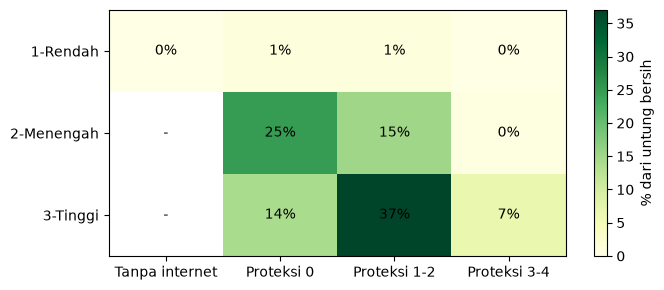

In [2]:
p = (t.pivot(index="monthly_charge_band", columns="keterlibatan", values="porsi_untung")
       .reindex(columns=URUT))
fig, ax = plt.subplots(figsize=(7, 3))
im = ax.imshow(p.values * 100, cmap="YlGn", aspect="auto")
ax.set_xticks(range(len(URUT))); ax.set_xticklabels(URUT)
ax.set_yticks(range(len(p))); ax.set_yticklabels(p.index)
for i in range(p.shape[0]):
    for j in range(p.shape[1]):
        x = p.values[i, j]
        ax.text(j, i, "-" if np.isnan(x) else f"{x:.0%}", ha="center", va="center")
plt.colorbar(im, label="% dari untung bersih"); plt.tight_layout()
plt.savefig("../reports/figures/segment_profit.png", dpi=150); plt.show()

In [3]:
pop = v["senior_citizen"].mean()
for b in [5e6, 10e6, 21e6]:
    for s in ["untung", "risiko"]:
        tg, r = select_targets(v, b, P, s)
        print(f"Rp {b/1e6:.0f} juta | {s:7s} | lansia di target {tg['senior_citizen'].mean():.1%} "
              f"(populasi {pop:.1%}) | untung nyata Rp {r['kenyataan']/1e6:.1f} juta")

v["layak"] = v["ev"] > 0
print(v.groupby(["contract", "senior_citizen"])["layak"].agg(["size", "mean"]).round(3))

Rp 5 juta | untung  | lansia di target 32.6% (populasi 16.2%) | untung nyata Rp 47.7 juta
Rp 5 juta | risiko  | lansia di target 29.7% (populasi 16.2%) | untung nyata Rp 45.1 juta
Rp 10 juta | untung  | lansia di target 29.9% (populasi 16.2%) | untung nyata Rp 74.7 juta
Rp 10 juta | risiko  | lansia di target 28.5% (populasi 16.2%) | untung nyata Rp 72.2 juta
Rp 21 juta | untung  | lansia di target 22.8% (populasi 16.2%) | untung nyata Rp 92.7 juta
Rp 21 juta | risiko  | lansia di target 22.2% (populasi 16.2%) | untung nyata Rp 90.9 juta
                               size   mean
contract       senior_citizen             
Month-to-month 0               3068  0.824
               1                807  0.981
One year       0               1283  0.410
               1                190  0.705
Two year       0               1550  0.119
               1                145  0.214
